# Financial statement analysis: liquidity, leverage, profitability and DuPont

Comparison of three **fictional** European industrial mid-caps (Alpine Industries, Baltic Components, Iberia Machinery) over FY2023-FY2025, against an illustrative sector benchmark.

**Questions answered**
1. Can each company meet its short-term obligations (liquidity)?
2. How much debt does it carry and can it service it (leverage)?
3. How profitable is it and what drives its return on equity (profitability, DuPont)?
4. How does each company compare with the sector benchmark?

All figures are synthetic and generated by `scripts/make_sample_data.py`. To analyse real companies, replace `data/financials.csv` with figures from annual reports using the same columns.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fsa.ratios import GROUPS, compare_to_benchmark, compute_ratios, dupont_3, dupont_5

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"Alpine Industries": "#1f4e79", "Baltic Components": "#c0504d", "Iberia Machinery": "#4f9d69"}

fin = pd.read_csv("../data/financials.csv")
bench = pd.read_csv("../data/benchmark.csv").set_index("ratio")["value"]
ratios = compute_ratios(fin)
latest = ratios.xs(2025, level="year")
fin.groupby("company")[["revenue", "ebitda", "net_income"]].last()

,revenue,ebitda,net_income
company,,,
Alpine Industries,1272,203.5,95.9
Baltic Components,690,75.9,19.1
Iberia Machinery,1010,200.0,112.6


## 1. Ratio dashboard (FY2025)

In [2]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
table = latest.T
table.insert(len(table.columns), "Benchmark", bench)
for group, cols in GROUPS.items():
    print(group)
    display(table.loc[cols])

Liquidity


company,Alpine Industries,Baltic Components,Iberia Machinery,Benchmark
current_ratio,2.20,1.47,3.31,1.80
quick_ratio,1.43,0.81,2.64,1.00
cash_ratio,0.63,0.23,1.87,0.40


Leverage


company,Alpine Industries,Baltic Components,Iberia Machinery,Benchmark
debt_to_equity,0.59,1.02,0.12,0.70
net_debt_to_ebitda,1.97,3.23,-0.97,2.00
interest_coverage,6.15,2.59,35.11,5.50
debt_to_assets,0.33,0.43,0.10,0.32


Profitability


company,Alpine Industries,Baltic Components,Iberia Machinery,Benchmark
gross_margin,0.34,0.27,0.41,0.32
ebitda_margin,0.16,0.11,0.20,0.14
ebit_margin,0.12,0.06,0.15,0.10
net_margin,0.08,0.03,0.11,0.06
roa,0.06,0.03,0.09,0.05
roe,0.10,0.07,0.11,0.11


Efficiency


company,Alpine Industries,Baltic Components,Iberia Machinery,Benchmark
asset_turnover,0.76,1.02,0.77,0.85
dso,55.01,62.00,47.99,58.00
dio,80.00,95.00,70.01,85.00
dpo,60.00,52.03,64.99,58.00
cash_conversion_cycle,75.01,104.97,53.01,85.00


## 2. Liquidity

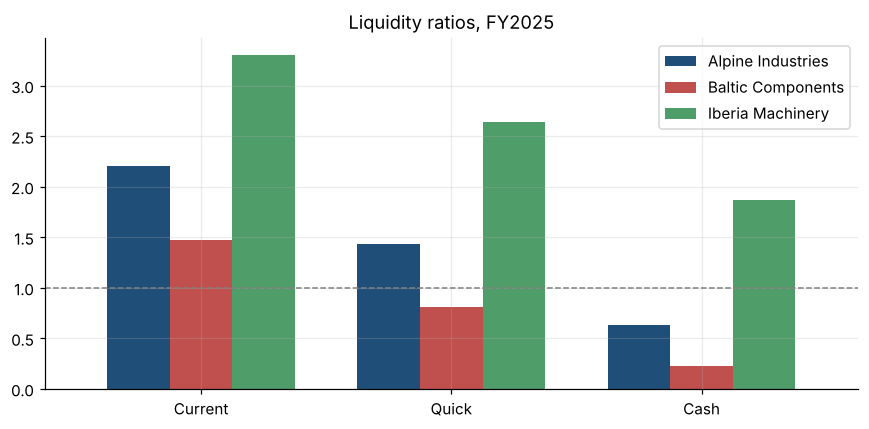

In [3]:
cols = ["current_ratio", "quick_ratio", "cash_ratio"]
ax = latest[cols].T.plot(kind="bar", color=[COLORS[c] for c in latest.index], figsize=(8, 4), width=0.75)
for r, v in bench[cols].items():
    pass
ax.set_title("Liquidity ratios, FY2025"); ax.set_xlabel(""); ax.set_xticklabels(["Current", "Quick", "Cash"], rotation=0)
ax.axhline(1, color="grey", lw=1, ls="--"); ax.legend(title="")
plt.tight_layout(); plt.savefig("../docs/liquidity.png"); plt.show()

## 3. Leverage and debt service

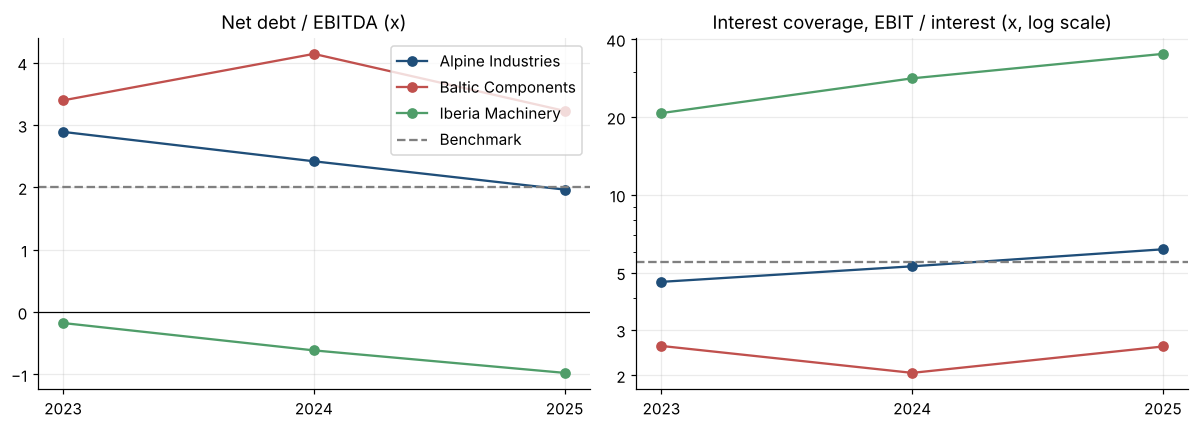

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for company, g in ratios.groupby(level="company"):
    g = g.droplevel("company")
    axes[0].plot(g.index, g["net_debt_to_ebitda"], marker="o", color=COLORS[company], label=company)
    axes[1].plot(g.index, g["interest_coverage"], marker="o", color=COLORS[company], label=company)
axes[0].axhline(0, color="black", lw=0.8); axes[0].axhline(bench["net_debt_to_ebitda"], color="grey", ls="--", label="Benchmark")
axes[0].set_title("Net debt / EBITDA (x)"); axes[0].legend(loc="upper right")
from matplotlib.ticker import NullFormatter, ScalarFormatter
axes[1].set_yscale("log"); axes[1].set_yticks([2, 3, 5, 10, 20, 40]); axes[1].yaxis.set_major_formatter(ScalarFormatter()); axes[1].yaxis.set_minor_formatter(NullFormatter()); axes[1].axhline(bench["interest_coverage"], color="grey", ls="--")
axes[1].set_title("Interest coverage, EBIT / interest (x, log scale)")
for ax in axes: ax.set_xticks([2023, 2024, 2025])
plt.tight_layout(); plt.savefig("../docs/leverage.png"); plt.show()

## 4. Profitability

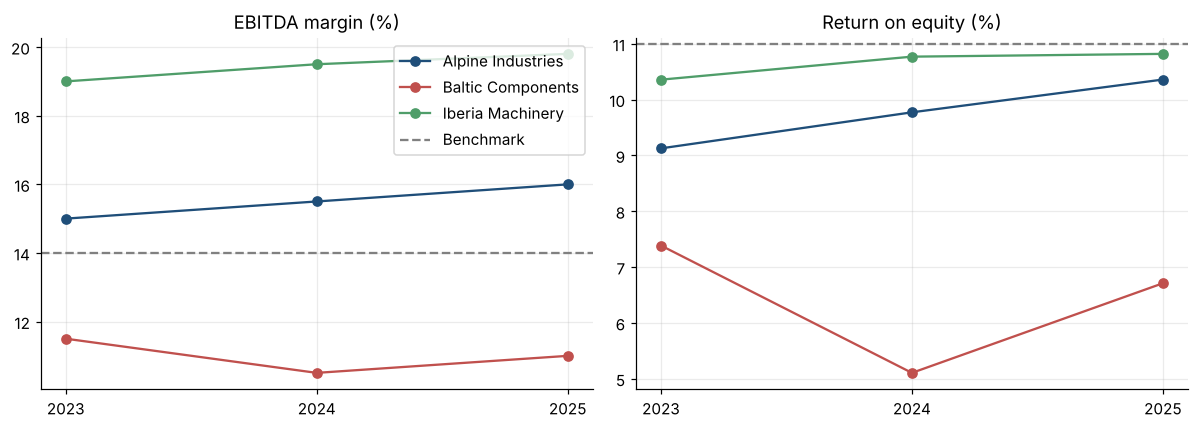

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for company, g in ratios.groupby(level="company"):
    g = g.droplevel("company")
    axes[0].plot(g.index, g["ebitda_margin"] * 100, marker="o", color=COLORS[company], label=company)
    axes[1].plot(g.index, g["roe"] * 100, marker="o", color=COLORS[company], label=company)
axes[0].axhline(bench["ebitda_margin"] * 100, color="grey", ls="--", label="Benchmark"); axes[0].set_title("EBITDA margin (%)"); axes[0].legend()
axes[1].axhline(bench["roe"] * 100, color="grey", ls="--"); axes[1].set_title("Return on equity (%)")
for ax in axes: ax.set_xticks([2023, 2024, 2025])
plt.tight_layout(); plt.savefig("../docs/profitability.png"); plt.show()

## 5. DuPont decomposition of ROE

**3-step:** ROE = net margin x asset turnover x equity multiplier. **5-step** splits the net margin into tax burden, interest burden and EBIT margin.

In [6]:
d3 = dupont_3(fin).xs(2025, level="year")
d3.assign(roe_check=d3["net_margin"] * d3["asset_turnover"] * d3["equity_multiplier"])

,net_margin,asset_turnover,equity_multiplier,roe,roe_check
company,,,,,
Alpine Industries,0.08,0.76,1.80,0.10,0.10
Baltic Components,0.03,1.02,2.37,0.07,0.07
Iberia Machinery,0.11,0.77,1.26,0.11,0.11


In [7]:
d5 = dupont_5(fin).xs(2025, level="year")
d5

,tax_burden,interest_burden,ebit_margin,asset_turnover,equity_multiplier,roe
company,,,,,,
Alpine Industries,0.75,0.84,0.12,0.76,1.80,0.10
Baltic Components,0.75,0.61,0.06,1.02,2.37,0.07
Iberia Machinery,0.75,0.97,0.15,0.77,1.26,0.11


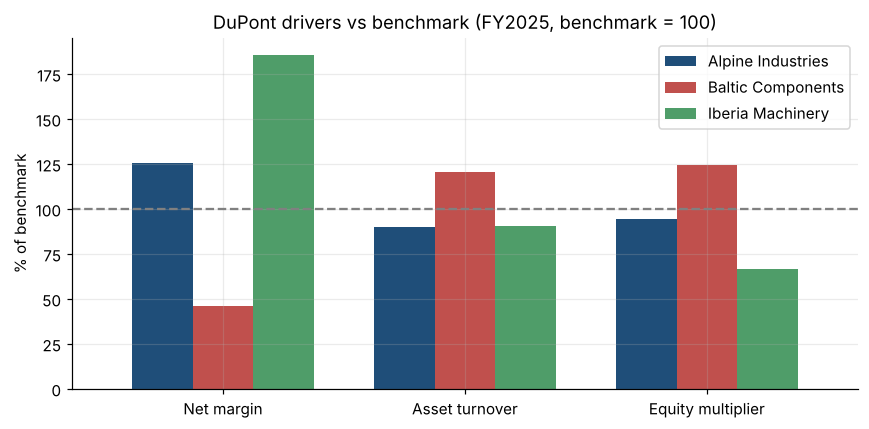

In [8]:
# Each factor relative to the benchmark: shows what drives ROE differences
factors = ["net_margin", "asset_turnover", "equity_multiplier"]
rel = latest[factors].div(bench[factors]) * 100
ax = rel.T.plot(kind="bar", color=[COLORS[c] for c in rel.index], figsize=(8, 4), width=0.75)
ax.axhline(100, color="grey", ls="--"); ax.set_ylabel("% of benchmark")
ax.set_xticklabels(["Net margin", "Asset turnover", "Equity multiplier"], rotation=0)
ax.set_title("DuPont drivers vs benchmark (FY2025, benchmark = 100)"); ax.legend(title="")
plt.tight_layout(); plt.savefig("../docs/dupont.png"); plt.show()

## 6. Comparison with the sector benchmark

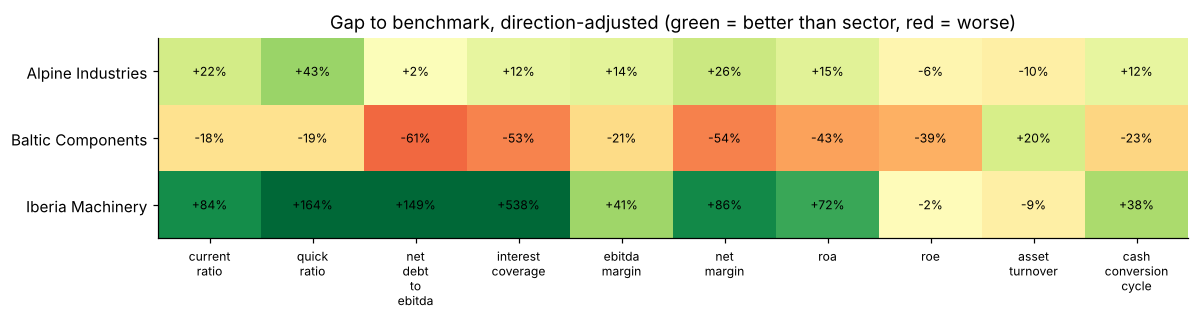

ratio,current_ratio,quick_ratio,net_debt_to_ebitda,interest_coverage,ebitda_margin,net_margin,roa,roe,asset_turnover,cash_conversion_cycle
company,,,,,,,,,,
Alpine Industries,better,better,in line,better,better,better,better,worse,worse,better
Baltic Components,worse,worse,worse,worse,worse,worse,worse,worse,better,worse
Iberia Machinery,better,better,better,better,better,better,better,in line,worse,better


In [9]:
cmp = compare_to_benchmark(latest, bench)
key = ["current_ratio", "quick_ratio", "net_debt_to_ebitda", "interest_coverage", "ebitda_margin",
       "net_margin", "roa", "roe", "asset_turnover", "cash_conversion_cycle"]
score = cmp[cmp["ratio"].isin(key)].pivot(index="company", columns="ratio", values="score")[key]
verdict = cmp[cmp["ratio"].isin(key)].pivot(index="company", columns="ratio", values="verdict")[key]

fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(score.clip(-1, 1).to_numpy(), cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(key))); ax.set_xticklabels([k.replace("_", "\n") for k in key], fontsize=8)
ax.set_yticks(range(len(score))); ax.set_yticklabels(score.index)
for i in range(score.shape[0]):
    for j in range(score.shape[1]):
        ax.text(j, i, f"{score.iat[i, j]:+.0%}", ha="center", va="center", fontsize=8)
ax.grid(False); ax.set_title("Gap to benchmark, direction-adjusted (green = better than sector, red = worse)")
plt.tight_layout(); plt.savefig("../docs/benchmark.png"); plt.show()
verdict

## 7. Conclusions

*(Based on the fictional FY2025 figures above.)*

- **Iberia Machinery is the strongest and safest.** It holds more cash than debt (net debt / EBITDA below zero), covers interest more than 30 times and has the highest EBITDA margin. Its ROE is reached with very little leverage (equity multiplier of 1.3x), so the return is of high quality.
- **Alpine Industries is balanced.** Liquidity is comfortable, leverage is close to the sector median and the EBITDA margin improved every year (15.0% to 16.0%). ROE is similar to Iberia's but relies on moderate leverage.
- **Baltic Components is the weak spot.** Net debt is above 3x EBITDA, interest cover is only about 2.6x, net margin is under 3% and the cash conversion cycle exceeds 100 days. Its asset turnover is the highest of the three, so the issue is margin and leverage, not asset use.
- **Similar ROE can hide very different risk.** DuPont shows Alpine and Iberia earn their ROE mainly through margins, while Baltic's lower ROE depends on higher leverage and turnover.

**Limits:** ratios use year-end balances (not averages), figures are synthetic, and a sector benchmark of three peers is for illustration only.